# Regridding: 2 m temperature on a 200 m grid over Valais

This example illustrates {func}`~grid_process.grid_interp.interp2grid` with four methods:

- `nearest`: value of the nearest source grid point;
- `linear`: linear interpolation (bilinear on regular grids, on a triangulation for unstructured grids);
- `idw`: inverse distance weighting of the `k` nearest grid points;
- `temp_fixgrad`: among the source grid points within `r_search` grid spacings, the one with the most
  similar altitude, corrected for the remaining altitude difference with a fixed lapse rate
  (6 K/km by default).

The 2 m temperature of IFS-HRES (regular 0.1° grid, about 9 km) and of the ICON-CH2 control member
(unstructured grid, about 2 km) is regridded to the 200 m digital height model of swisstopo over
Valais, a region of deep valleys and high mountains, for the same valid time.

*Data: ECMWF open data, © ECMWF, CC BY 4.0. MeteoSwiss open data, CC BY 4.0, source: MeteoSwiss.
DHM25/200, © swisstopo. Country borders: Natural Earth.*

In [1]:
import datetime as dt
import os
import re
import time
import timeit

import pyproj  # noqa: F401  # import before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import eccodes_cosmo_resources

# ICON GRIB files need the COSMO definitions of ecCodes
os.environ["ECCODES_DEFINITION_PATH"] = str(eccodes_cosmo_resources.get_definitions_path())
os.environ["ECCODES_VERSION_CHECK_OFF"] = "1"

import cartopy.crs as ccrs
import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
import pandas as pd
import pooch
import requests
import xarray as xr

import grid_process.grid_interp as gri
import grid_process.timeseries as tms

METHODS = {
    "nearest": {"method": "nearest"},
    "linear": {"method": "linear"},
    "idw": {"method": "idw", "k": 4, "weight_power": 2},
    "temp_fixgrad": {"method": "temp_fixgrad"},
}
LEAD_H_IFS = 24  # lead time [h] of the latest IFS-HRES run defining the common valid time

  from .autonotebook import tqdm as notebook_tqdm


## Destination grid

The DHM25/200 height model of swisstopo is an ESRI ASCII grid in the Swiss LV03 coordinate system
(EPSG:21781). We read it into a dataset with 1D `x`/`y` coordinates of the pixel centres, the CRS in
the `crs` attribute and the altitude in a `surface_altitude` coordinate, which `temp_fixgrad` needs.
The subregion covers Valais, from Lake Geneva to the Goms valley (451 × 641 cells).

In [2]:
def read_esri_ascii(path: str, crs: str) -> xr.Dataset:
    """Read an ESRI ASCII grid (rows may be wrapped over several lines)."""
    with open(path, "rb") as f:
        header = dict(f.readline().decode().lower().split() for _ in range(6))
        header = {key: float(value) for key, value in header.items()}
        nrows, ncols = int(header["nrows"]), int(header["ncols"])
        values = np.array(f.read().split(), dtype="float32").reshape(nrows, ncols)
    values[values == header["nodata_value"]] = np.nan
    size = header["cellsize"]
    x = header["xllcorner"] + size * (np.arange(ncols) + 0.5)
    y = header["yllcorner"] + size * (np.arange(nrows)[::-1] + 0.5)  # first row is the northernmost
    return xr.Dataset(
        coords={"x": x, "y": y, "surface_altitude": (("y", "x"), values, {"units": "m"})}, attrs={"crs": crs}
    )


dhm_path = pooch.retrieve(
    "https://data.geo.admin.ch/ch.swisstopo.digitales-hoehenmodell_25/data.zip",
    known_hash="sha256:9d283f198f829202e09859954d54553001f7ff1a79e3614ad47ac9cd98641887",
    processor=pooch.Unzip(members=["DHM200.asc"]),
)[0]
dst_grid = read_esri_ascii(dhm_path, "EPSG:21781").sel(x=slice(552000, 680000), y=slice(165000, 75000))
dst_grid

<xarray.Dataset> Size: 1MB
Dimensions:           (x: 641, y: 451)
Coordinates:
  * x                 (x) float64 5kB 5.52e+05 5.522e+05 ... 6.798e+05 6.8e+05
    surface_altitude  (y, x) float32 1MB 605.7 630.2 666.2 678.0 ... nan nan nan
  * y                 (y) float64 4kB 1.65e+05 1.648e+05 ... 7.52e+04 7.5e+04
Data variables:
    *empty*
Attributes:
    crs:      EPSG:21781

## Source data

The common valid time is the latest IFS-HRES run + `LEAD_H_IFS`. For ICON-CH2 we take the oldest run
still on the MeteoSwiss portal, which is always complete, at the lead time reaching the same valid
time. Each model comes with its own orography for `temp_fixgrad`: the surface geopotential `z` at step
0 for IFS, `HSURF` for ICON. IFS open data are global fields, cropped right after loading with a wide
margin. ICON files cover the full model domain; `interp2grid` itself restricts the source data to the
destination domain.

In [3]:
OD_ROOT = "https://data.ecmwf.int/forecasts"
IFS_BBOX = {"latitude": slice(47.5, 45.0), "longitude": slice(5.5, 10.0)}  # Valais with a wide margin


def index_url(date: str, hour: int, step: int) -> str:
    return f"{OD_ROOT}/{date}/{hour:02d}z/ifs/0p1/oper/{date}{hour:02d}0000-{step}h-oper-fc-sfc.index"


def latest_ifs_run(step: int) -> tuple[str, int]:
    """Latest IFS-HRES run on the ECMWF open data portal with the given step already published."""
    dates = sorted(set(re.findall(r'href="/forecasts/(\d{8})/"', requests.get(f"{OD_ROOT}/", timeout=30).text)))
    for date in reversed(dates):
        for hour in (18, 12, 6, 0):
            if requests.head(index_url(date, hour, step), timeout=30).ok:
                return date, hour
    raise RuntimeError("No IFS-HRES run found on the open data portal")


def open_ifs(**request) -> ekd.FieldList:
    return ekd.from_source(
        "ecmwf-open-data", model="ifs", resol="0p1", stream="oper", type="fc", date=int(date), time=hour, **request
    ).to_fieldlist()


date, hour = latest_ifs_run(LEAD_H_IFS)
ds_ifs = open_ifs(param="2t", step=LEAD_H_IFS).to_xarray(time_dims=["forecast_reference_time", "step"], squeeze=False)
# with the COSMO definitions of ecCodes (set above for ICON) the IFS fields get COSMO names: take the single variable
ds_ifs = ds_ifs.squeeze(["level", "level_type"], drop=True).sel(IFS_BBOX)
ds_ifs = ds_ifs.rename({next(iter(ds_ifs.data_vars)): "T_2M"})
ds_z = open_ifs(param="z", levtype="sfc", step=0).to_xarray()
z_surf = next(iter(ds_z.data_vars.values())).squeeze().reset_coords(drop=True).sel(IFS_BBOX)
ds_ifs = ds_ifs.assign_coords(surface_altitude=(z_surf / 9.80665).astype("float32")).astype("float32")
valid_time = pd.Timestamp(ds_ifs.forecast_reference_time.item()) + pd.Timedelta(hours=LEAD_H_IFS)
print(f"IFS-HRES run {date} {hour:02d} UTC, valid time {valid_time} UTC")

IFS-HRES run 20261027 06 UTC, valid time 2026-10-28 06:00:00 UTC


In [4]:
COLLECTION = "ogd-forecasting-icon-ch2"


def oldest_icon_run(variable: str, margin: dt.timedelta = dt.timedelta(minutes=30)) -> str:
    """Oldest run whose first lead time (uploaded, hence deleted, first) is still available."""
    response = requests.post(
        "https://data.geo.admin.ch/api/stac/v1/search",
        json={
            "collections": [f"ch.meteoschweiz.{COLLECTION}"],
            "forecast:variable": variable,
            "forecast:perturbed": False,
            "forecast:horizon": "P0DT00H00M00S",
            "sortby": [{"field": "properties.datetime", "direction": "asc"}],
        },
        timeout=30,
    )
    now = dt.datetime.now(dt.timezone.utc)
    for item in response.json()["features"]:
        if dt.datetime.fromisoformat(item["properties"]["expires"]) > now + margin:
            return item["properties"]["forecast:reference_datetime"]
    raise RuntimeError("No run found on the open data portal")


ref_time = oldest_icon_run("T_2M")
lead_h = int((valid_time - pd.Timestamp(ref_time).tz_convert(None)) / pd.Timedelta(hours=1))
print(f"ICON-CH2 run {ref_time}, lead time {lead_h} h")

ds_icon = ekd.from_source(
    "meteoswiss-opendata",
    collection=COLLECTION,
    variable="T_2M",
    ref_time=ref_time,
    perturbed=False,
    lead_time=[f"P0DT{lead_h}H"],
).to_xarray(time_dims=["forecast_reference_time", "step"], squeeze=False)
ds_icon = ds_icon.squeeze(["member", "level", "level_type"], drop=True).rename_dims(values="cell")
constants = ekd.from_source("meteoswiss-opendata-constants", collection=COLLECTION, asset="horizontal")
hsurf = constants.to_fieldlist().sel({"parameter.variable": "HSURF"})[0].to_numpy()
ds_icon = ds_icon.assign_coords(HSURF=("cell", hsurf.astype("float32"))).astype("float32")

models = {}
for name, ds in {"IFS-HRES": ds_ifs, "ICON-CH2": ds_icon}.items():
    ds = tms.setindex_validtime(ds.load())  # forecast_reference_time and step -> time
    ds["T_2M"] = (ds["T_2M"] - 273.15).assign_attrs(units="°C")
    models[name] = ds
models["ICON-CH2"]

ICON-CH2 run 2026-10-27T00:00:00Z, lead time 30 h


<xarray.Dataset> Size: 7MB
Dimensions:                  (time: 1, cell: 283876)
Coordinates:
  * time                     (time) datetime64[us] 8B 2026-10-28T06:00:00
    forecast_reference_time  (time) datetime64[us] 8B 2026-10-27
    latitude                 (cell) float64 2MB 46.97 46.98 ... 50.06 50.05
    longitude                (cell) float64 2MB -0.1542 -0.1638 ... 12.83 12.81
    HSURF                    (cell) float32 1MB 94.11 87.99 ... 626.5 682.7
Dimensions without coordinates: cell
Data variables:
    T_2M                     (time, cell) float32 1MB 11.35 11.35 ... 6.4 6.691
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Interpolation

Each method is called once per model, and the duration of this first call is kept for the benchmark
below. DHM25/200 has no altitude in parts of the box outside Switzerland, where `temp_fixgrad` returns
NaN. For a like-for-like comparison, the outputs of all methods are masked there.

In [5]:
results, first_call = {}, {}
for name, ds in models.items():
    results[name], first_call[name] = {}, {}
    for label, kwargs in METHODS.items():
        t0 = time.perf_counter()
        out = gri.interp2grid(ds, dst_grid, **kwargs)
        first_call[name][label] = time.perf_counter() - t0
        results[name][label] = out.where(dst_grid.surface_altitude.notnull())
results["ICON-CH2"]["temp_fixgrad"]

<xarray.Dataset> Size: 2MB
Dimensions:                  (y: 451, x: 641, time: 1)
Coordinates:
  * y                        (y) float64 4kB 1.65e+05 1.648e+05 ... 7.5e+04
  * x                        (x) float64 5kB 5.52e+05 5.522e+05 ... 6.8e+05
    surface_altitude         (y, x) float32 1MB 605.7 630.2 666.2 ... nan nan
  * time                     (time) datetime64[us] 8B 2026-10-28T06:00:00
    forecast_reference_time  (time) datetime64[us] 8B 2026-10-27
Data variables:
    T_2M                     (y, x, time) float32 1MB 9.23 9.083 ... nan nan
Attributes:
    institution:  ECMWF
    crs:          EPSG:21781

## Visual comparison

One figure per model, with the same colour scale for both.

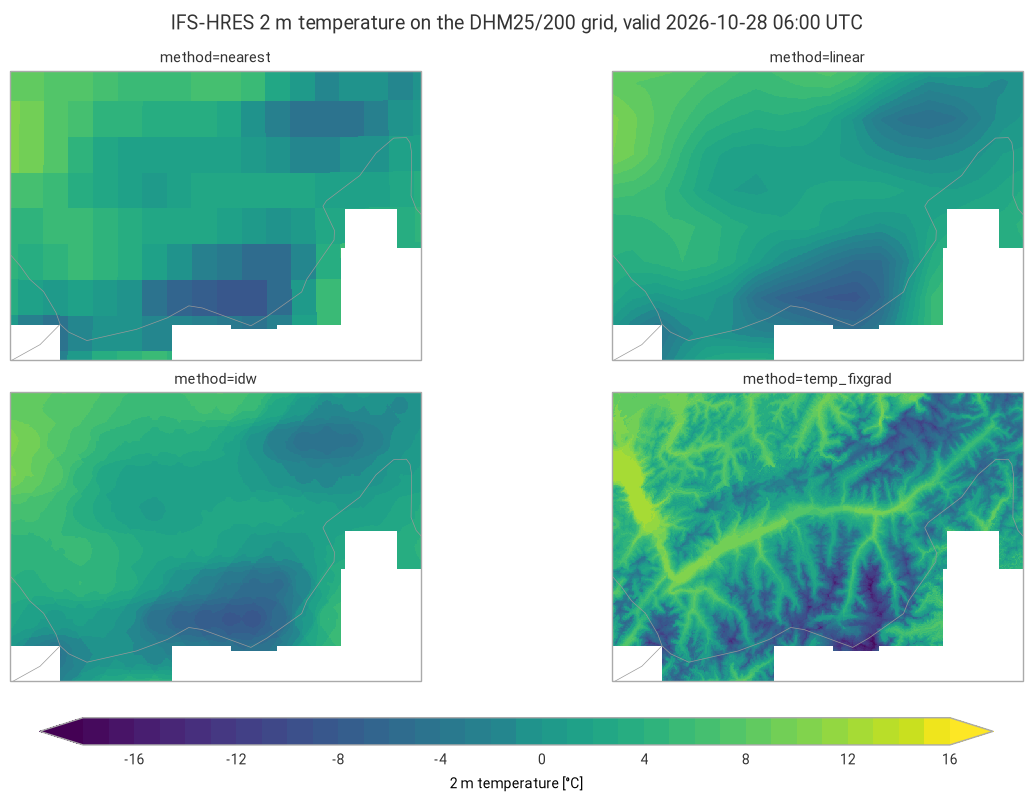

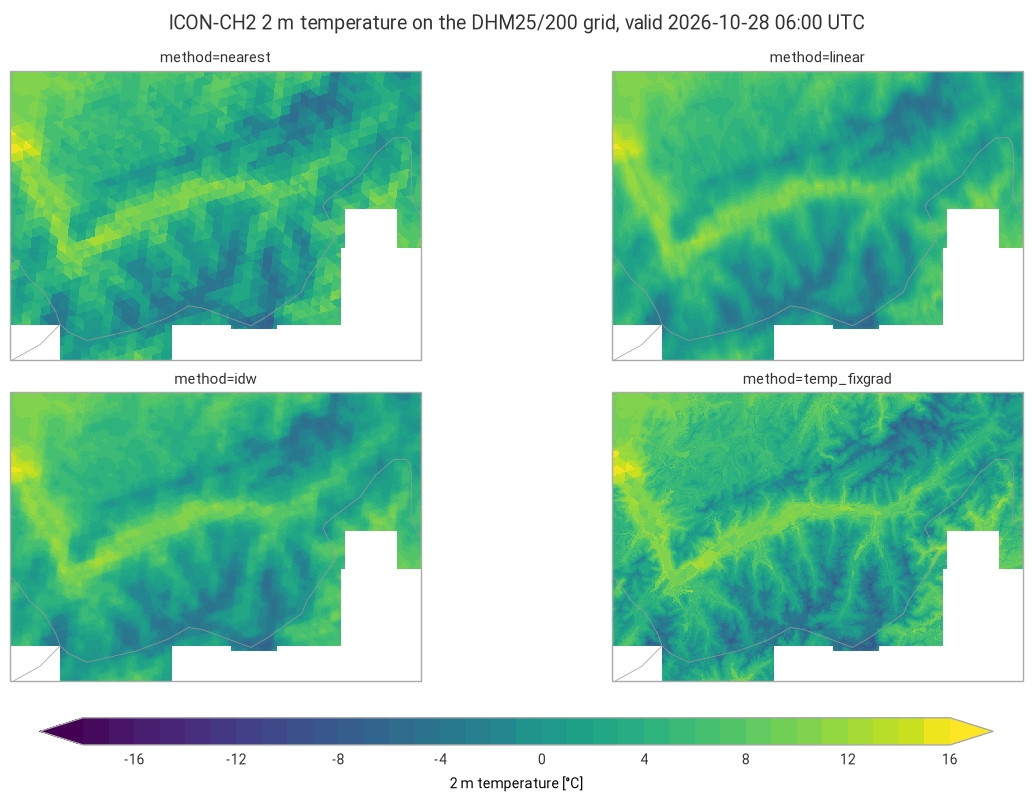

In [6]:
lv03 = ccrs.epsg(21781)
t_min = min(float(res[m]["T_2M"].min()) for res in results.values() for m in METHODS)
t_max = max(float(res[m]["T_2M"].max()) for res in results.values() for m in METHODS)
style = ekp.styles.Style(
    levels=np.arange(np.floor(t_min), np.ceil(t_max) + 1, 1), colors="viridis", extend="both", units="°C"
)

for name, res in results.items():
    fig = ekp.Figure(rows=2, columns=2, figsize=(12, 7.5), crs=lv03)
    for i, (label, out) in enumerate(res.items()):
        subplot = fig.add_map(i // 2, i % 2)
        subplot.pcolormesh(out["T_2M"].squeeze().values, x=out.x.values, y=out.y.values, style=style, transform=lv03)
        subplot.title(f"method={label}")
    fig.borders()
    fig.legend(label="2 m temperature [°C]")
    fig.title(f"{name} 2 m temperature on the DHM25/200 grid, valid {valid_time:%Y-%m-%d %H:%M} UTC")
    fig.show()

## Performance benchmark

The first call includes building the neighbour search structures and reprojecting the coordinates,
which `grid_process` caches. Subsequent calls on the same grids (e.g. for other variables or runs) reuse
them: their runtime is the mean ± standard deviation over 5 repetitions.

In [7]:
def benchmark(func, data, target, methods: dict, first_call: dict, repeat: int = 5) -> pd.DataFrame:
    rows = []
    for label, kwargs in methods.items():
        warm = np.array(timeit.repeat(lambda: func(data, target, **kwargs), number=1, repeat=repeat))
        rows.append(
            {
                "method": label,
                "kwargs": ", ".join(f"{k}={v}" for k, v in kwargs.items() if k != "method"),
                "first call [s]": first_call[label],
                "subsequent calls [s]": f"{warm.mean():.3f} ± {warm.std():.3f}",
            }
        )
    return pd.DataFrame(rows).set_index("method").round(3)


print(f"destination grid: {dst_grid.y.size} × {dst_grid.x.size} cells")
pd.concat(
    {name: benchmark(gri.interp2grid, ds, dst_grid, METHODS, first_call[name]) for name, ds in models.items()},
    names=["model"],
)

destination grid: 451 × 641 cells


kwargs  first call [s]  \
model    method                                              
IFS-HRES nearest                                     0.256   
         linear                                      0.065   
         idw           k=4, weight_power=2           0.178   
         temp_fixgrad                                0.335   
ICON-CH2 nearest                                     0.137   
         linear                                      0.113   
         idw           k=4, weight_power=2           0.187   
         temp_fixgrad                                0.288   

                      subsequent calls [s]  
model    method                             
IFS-HRES nearest             0.042 ± 0.001  
         linear              0.053 ± 0.001  
         idw                 0.106 ± 0.004  
         temp_fixgrad        0.176 ± 0.004  
ICON-CH2 nearest             0.092 ± 0.009  
         linear              0.112 ± 0.001  
         idw                 0.107 ± 0.003  
         temp_fixgrad        0.185 ± 0.009

## Takeaways

- With IFS-HRES (9 km), `nearest` shows the source grid boxes. `linear` and `idw` are smooth, but like
  the model they ignore the terrain at 200 m: the Rhône valley gets the temperature of a much higher
  model altitude, and the summits of a much lower one.
- `temp_fixgrad` restores the terrain structure by correcting with the altitude difference between the
  source grid point and the 200 m grid: warmer valleys, colder summits. ICON-CH2 (2 km) already
  resolves the main valleys, so its correction is smaller.
- The fixed lapse rate (`grad`, 6 K/km by default) is a simplification and cannot reproduce
  temperature inversions.
- Every method regrids both models to the 289 000 cells of the destination grid in well under a
  second. `temp_fixgrad` is the most expensive.